# 🌍 PopuLens: How the World's Population Is Distributed

**Prodigy InfoTech Data Science Internship – Task 01**
*Author: Vaishnav Kumbhar ([@VaishnavK9](https://github.com/VaishnavK9))*

> **Task:** Create bar charts and histograms to visualize the distribution of a categorical or continuous variable.

This notebook looks at the World Bank's total population indicator (`SP.POP.TOTL`) for **217 countries from 1960 to 2024**. It looks at the data from two angles:

| Variable | Type | Charts |
|---|---|---|
| Country population | Continuous | Histogram (linear and log), top-15 bar chart, growth lines, world map |
| Region and income group | Categorical | Bar charts of population and country counts |

**Contents**
1. Setup
2. Inspecting the raw data
3. Cleaning: from a wide spreadsheet to a tidy table
4. How are country populations distributed? (histogram)
5. Which countries are the largest? (bar chart)
6. Where do people live? (region bar chart)
7. Countries vs people by income group (categorical distribution)
8. How did the giants grow? (line chart)
9. Bonus: interactive world map
10. Conclusions

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's `src` package importable whether the notebook runs from
# the project root or from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src.data_loader import FIGURES_DIR, inspect_dataframe, load_raw_data
from src.cleaning import clean_population_data, save_processed, snapshot, latest_year
from src.visualize import (
    human_format,
    income_totals,
    plot_choropleth,
    plot_income_groups,
    plot_population_by_region,
    plot_population_growth,
    plot_population_histogram,
    plot_top_countries,
    region_totals,
)

%matplotlib inline
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.1f}".format)

## 2. Inspecting the raw data

The World Bank bundle has three CSV files. Before changing anything, we look at each one's **shape, columns, dtypes and missing values**.

In [2]:
raw = load_raw_data()
pop_summary = inspect_dataframe(raw.population, "Population (wide, years as columns)")
meta_summary = inspect_dataframe(raw.country_meta, "Country metadata")
_ = inspect_dataframe(raw.indicator_meta, "Indicator metadata")

Population (wide, years as columns): 266 rows x 69 columns
Columns: ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '...', '2022', '2023', '2024']
Dtypes : {'float64': 65, 'str': 4}
Nulls  : 95 total across 65 column(s)

Country metadata: 265 rows x 5 columns
Columns: ['Country Code', 'Region', 'IncomeGroup', 'SpecialNotes', 'TableName']
Dtypes : {'str': 5}
Nulls  : 234 total across 3 column(s)

Indicator metadata: 1 rows x 4 columns
Columns: ['INDICATOR_CODE', 'INDICATOR_NAME', 'SOURCE_NOTE', 'SOURCE_ORGANIZATION']
Dtypes : {'str': 4}
Nulls  : 0 total across 0 column(s)



In [3]:
raw.population.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,...,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Population, total",SP.POP.TOTL,"54,922.0","55,578.0",...,"109,203.0","108,587.0","107,700.0","107,310.0","107,359.0","107,624.0"
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,"130,075,728.0","133,534,923.0",...,"675,950,189.0","694,446,100.0","713,090,928.0","731,821,393.0","750,503,764.0","769,294,618.0"
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,"9,035,043.0","9,214,083.0",...,"37,856,121.0","39,068,979.0","40,000,412.0","40,578,842.0","41,454,761.0","42,647,492.0"
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,"97,630,925.0","99,706,674.0",...,"463,365,429.0","474,569,351.0","485,920,997.0","497,387,180.0","509,398,589.0","521,764,076.0"
4,Angola,AGO,"Population, total",SP.POP.TOTL,"5,231,654.0","5,301,583.0",...,"32,375,632.0","33,451,132.0","34,532,429.0","35,635,029.0","36,749,906.0","37,885,849.0"


In [4]:
# Missing values per column in the country metadata
meta_summary

,dtype,non_null,nulls,null_pct
Country Code,str,265,0,0.0
Region,str,217,48,18.1
IncomeGroup,str,215,50,18.9
SpecialNotes,str,129,136,51.3
TableName,str,265,0,0.0


In [5]:
# Missing values per year column in the population file (only years with gaps)
pop_summary.loc[pop_summary["nulls"] > 0, ["nulls", "null_pct"]].T

,1960,1961,1962,1963,1964,1965,...,2019,2020,2021,2022,2023,2024
nulls,2.0,2.0,2.0,2.0,2.0,2.0,...,1.0,1.0,1.0,1.0,1.0,1.0
null_pct,0.8,0.8,0.8,0.8,0.8,0.8,...,0.4,0.4,0.4,0.4,0.4,0.4


In [6]:
print(raw.indicator_meta.loc[0, 'SOURCE_NOTE'])

Total population is based on the de facto definition of population, which counts all residents regardless of legal status or citizenship. The values shown are midyear estimates.


**What the inspection tells us**

* The population file has **266 rows**, but not all of them are countries. Rows like *World*, *Euro area*, *High income* and *IDA total* are **aggregates**. Leaving them in would double-count people and put "World" at the top of every ranking.
* In the metadata, **aggregates have an empty `Region`** (48 rows). This gives us a reliable way to filter them out.
* Two real countries, **Ethiopia and Venezuela**, have no `IncomeGroup` (the World Bank has temporarily unclassified them).
* Population gaps are rare: one row (`INX`, "Not classified") is completely empty, and **West Bank and Gaza** has no data before 1990.

## 3. Cleaning: from a wide spreadsheet to a tidy table

| # | Decision | Why |
|---|---|---|
| 1 | Skip the 4 metadata lines; drop empty `Unnamed` and constant `Indicator` columns | They hold no data |
| 2 | Keep only codes whose metadata has a `Region` | Removes 48 aggregates and the empty `INX` row |
| 3 | Reshape years from wide to long (`country, year, population`) | Tidy format for grouping and plotting |
| 4 | **Do not impute** missing population; drop those country-years | Invented headcounts would be misleading, and only 30 values (one territory, 1960–89) are affected |
| 5 | Label missing `IncomeGroup` as **"Not classified"** | Keeps Ethiopia's and Venezuela's 160M people in every total |
| 6 | Store `year` and `population` as integers | They are counts |

In [7]:
df, report = clean_population_data(raw)
print(report.summary())
save_processed(df)
df.head()

Raw rows in population file : 266
Aggregate rows removed      : 48
Codes without metadata      : INX
Real countries kept         : 217
IncomeGroup set to 'Not classified': Ethiopia, Venezuela, RB
Missing country-years dropped: West Bank and Gaza (30 yrs)
Long-format rows            : 14,075
Year range                  : 1960–2024


,country,code,region,income_group,year,population
0,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1960,9035043
1,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1961,9214083
2,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1962,9404406
3,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1963,9604487
4,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1964,9814318


In [8]:
YEAR = latest_year(df)
snap = snapshot(df, YEAR)

world_total = snap["population"].sum()
print(f"Countries in {YEAR}: {len(snap)}")
print(f"Sum of country populations: {human_format(world_total)}")

# Sanity check: our country sum should be close to the World Bank 'World' aggregate.
wld = raw.population.loc[raw.population["Country Code"] == "WLD", str(YEAR)].iloc[0]
print(f"World Bank 'World' row: {human_format(wld)} -> difference {abs(wld - world_total) / wld:.2%}")

Countries in 2024: 217
Sum of country populations: 8.12B
World Bank 'World' row: 8.14B -> difference 0.29%


The 217 countries add up to within **0.3%** of the World Bank's own *World* total, so the aggregate filter kept the real countries and dropped only the groupings. The small gap comes from territories that the World Bank counts in *World* but doesn't list as separate economies.

## 4. How are country populations distributed?

Population is a **continuous variable**, so a histogram is the natural chart. We plot it twice: on a linear axis, and on a log axis where each step is ×10.

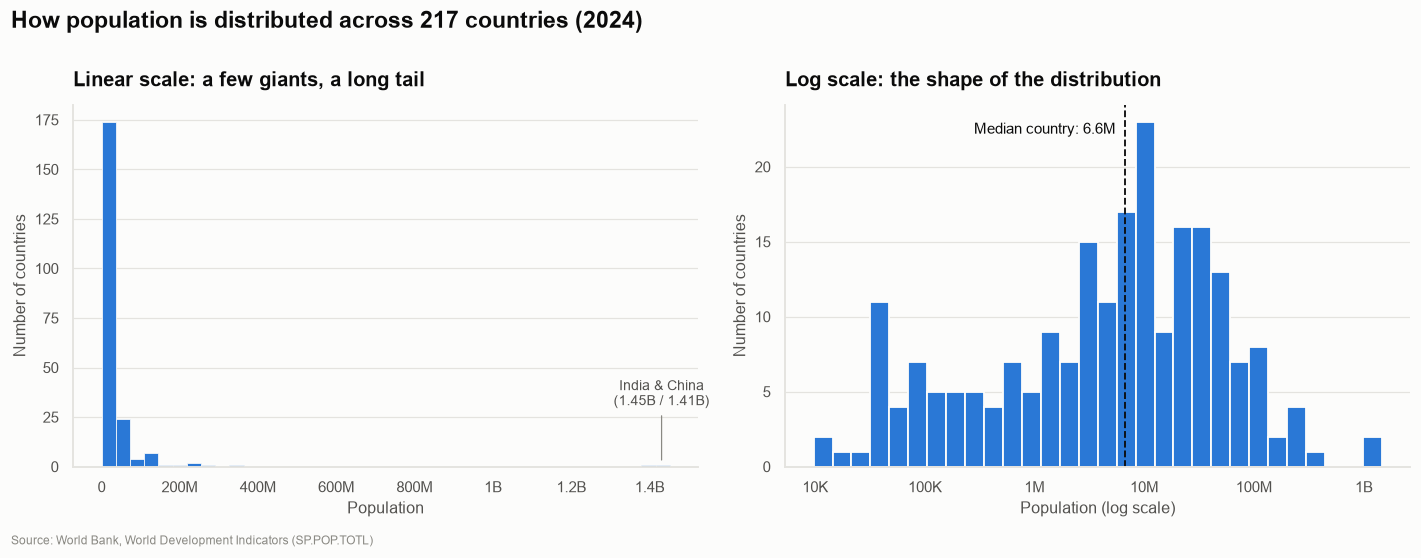

In [9]:
fig = plot_population_histogram(df, YEAR, save=True)
plt.show()

In [10]:
pop = snap["population"]
pd.Series({
    "Mean": human_format(pop.mean()),
    "Median": human_format(pop.median()),
    "Skewness": f"{pop.skew():.1f}",
    "Countries under 1M": int((pop < 1e6).sum()),
    "Countries over 100M": int((pop > 1e8).sum()),
    "Smallest": f"{snap.nsmallest(1, 'population')['country'].iloc[0]} ({human_format(pop.min())})",
}, name=str(YEAR)).to_frame()

,2024
Mean,37.4M
Median,6.6M
Skewness,8.8
Countries under 1M,57
Countries over 100M,16
Smallest,Tuvalu (9.6K)


**💡 Insight: country sizes are extremely right-skewed.**

* On the linear axis, about **80% of countries fall in the first bar**, and India and China sit alone at about 1.4B. A skewness of about **8.8** confirms the long tail.
* The **mean (37M) is almost 6× the median (6.6M)**. A handful of giants pull the average up, so the median is the better description of a "typical" country.
* On the log axis the shape becomes readable: most countries have **1M–100M** people, with a separate group of **57 micro-states under 1M**, such as Tuvalu with fewer than 10K.

## 5. Which countries are the largest?

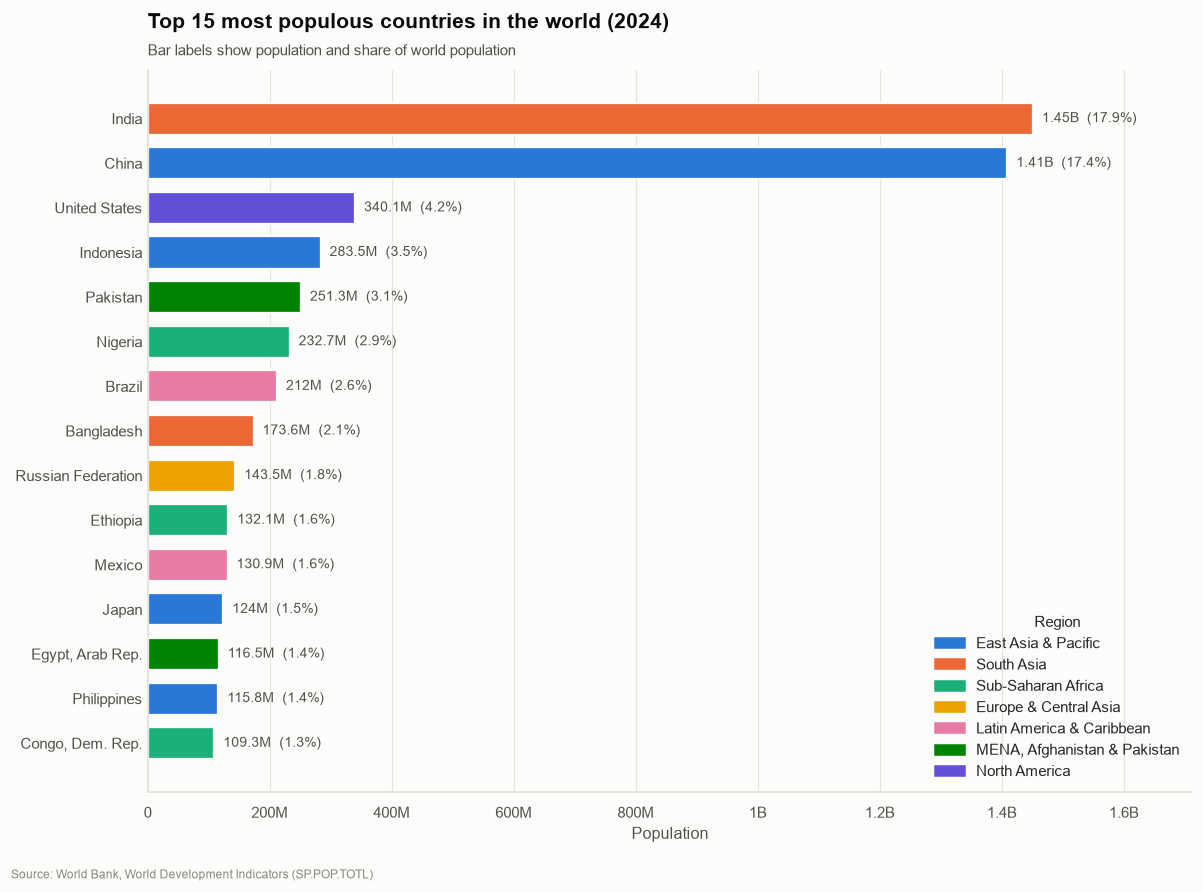

In [11]:
fig = plot_top_countries(df, YEAR, n=15, save=True)
plt.show()

In [12]:
ranked = snap.sort_values("population", ascending=False)
for n in (2, 10, 15):
    share = ranked["population"].head(n).sum() / world_total
    print(f"Top {n:>2} countries hold {share:.1%} of the world's population")
bottom_half = ranked["population"].tail(len(ranked) // 2).sum() / world_total
print(f"The smallest {len(ranked) // 2} countries together hold just {bottom_half:.1%}")

Top  2 countries hold 35.2% of the world's population
Top 10 countries hold 57.0% of the world's population
Top 15 countries hold 64.4% of the world's population
The smallest 108 countries together hold just 2.4%


**💡 Insight: population is highly concentrated.**

* **India (1.45B) and China (1.41B) alone hold 35% of humanity.** According to this data, India overtook China in **2021**.
* The **top 10 countries hold 57%** of the world's people, while the **smallest 108 countries together hold only about 2.4%**.
* The top 15 includes a country from **all seven regions**. Asia dominates, and three **Sub-Saharan African** countries (Nigeria, Ethiopia, DR Congo) are already in the list.

## 6. Where do people live?

Now we switch to a **categorical** variable: the World Bank region.

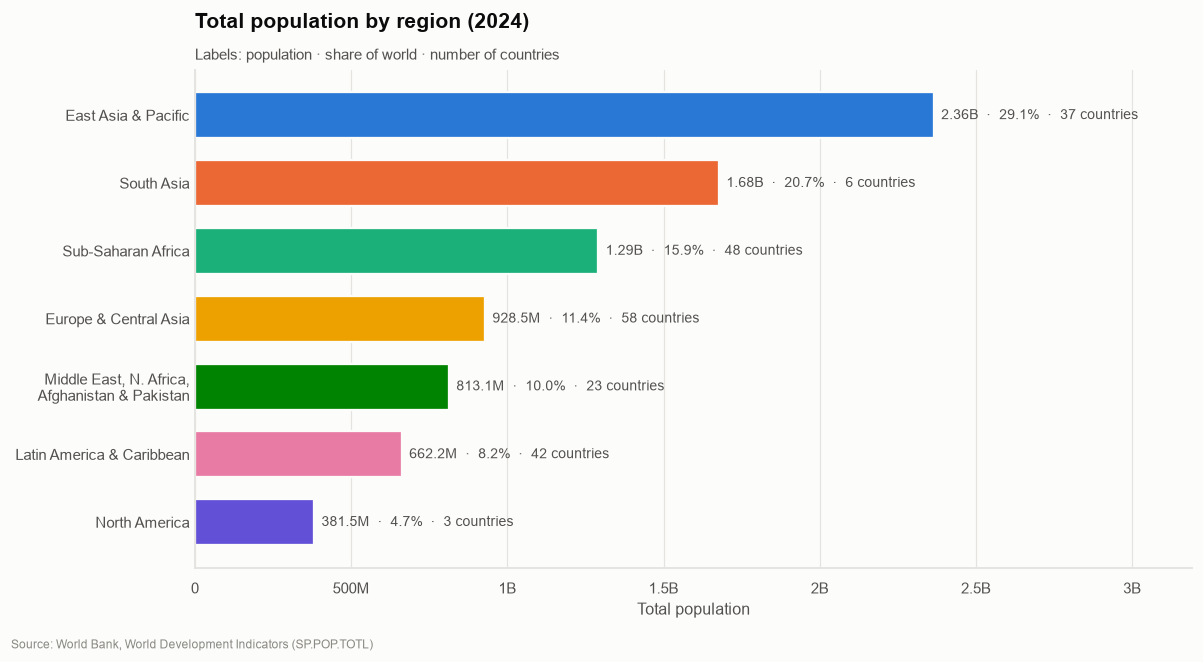

In [13]:
fig = plot_population_by_region(df, YEAR, save=True)
plt.show()

In [14]:
region_table = region_totals(df, YEAR).assign(population=lambda t: t["population"].map(human_format))
region_table

,region,population,countries,share_pct
0,East Asia & Pacific,2.36B,37,29.1
1,South Asia,1.68B,6,20.7
2,Sub-Saharan Africa,1.29B,48,15.9
3,Europe & Central Asia,928.5M,58,11.4
4,"Middle East, North Africa, Afghanistan & Pakistan",813.1M,23,10.0
5,Latin America & Caribbean,662.2M,42,8.2
6,North America,381.5M,3,4.7


**💡 Insight: country counts and population tell different stories.**

* **East Asia & Pacific** is the most populous region (2.4B, 29%).
* **South Asia** holds **one in five people on Earth in only 6 countries**, the highest population per country of any region.
* **Europe & Central Asia** has the most countries (58) but only 11% of the population.

## 7. Countries vs people by income group

The income group is an **ordered categorical** variable. We compare its distribution over **countries** with its distribution over **people**. These are two different measures, so they get two panels rather than one chart with two y-axes.

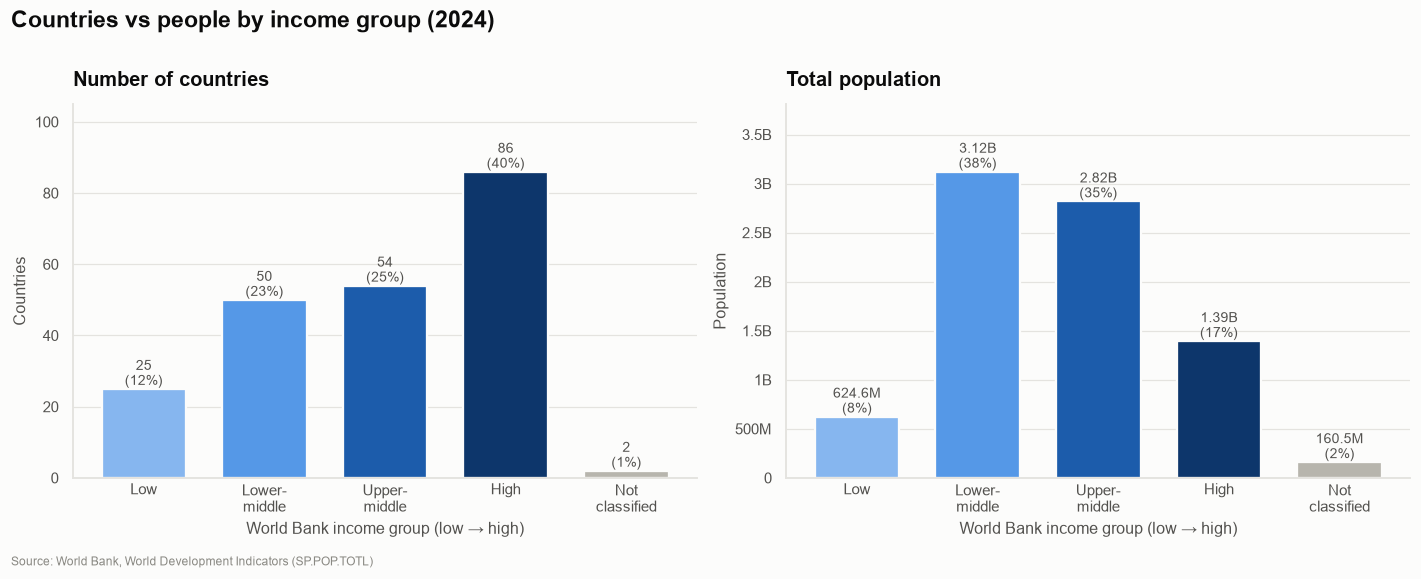

In [15]:
fig = plot_income_groups(df, YEAR, save=True)
plt.show()

In [16]:
income_totals(df, YEAR).assign(population=lambda t: t["population"].map(human_format))

,income_group,countries,population,country_pct,population_pct
0,Low income,25,624.6M,11.5,7.7
1,Lower middle income,50,3.12B,23.0,38.4
2,Upper middle income,54,2.82B,24.9,34.7
3,High income,86,1.39B,39.6,17.2
4,Not classified,2,160.5M,0.9,2.0


**💡 Insight: most countries are rich, but most people are not.**

* **High-income** is the largest group by country count (**86 countries, 40%**) but holds only **17% of the population**.
* **Middle-income countries hold 73% of humanity** (lower-middle 38%, upper-middle 35%). This is where India, China, Indonesia, Pakistan and Nigeria sit.
* **Low-income** countries are 12% of countries and about 8% of people.

## 8. How did the giants grow? (1960–2024)

The left panel shows absolute population. The right panel indexes each country to **1960 = 100**, so we can compare growth *rates* regardless of size.

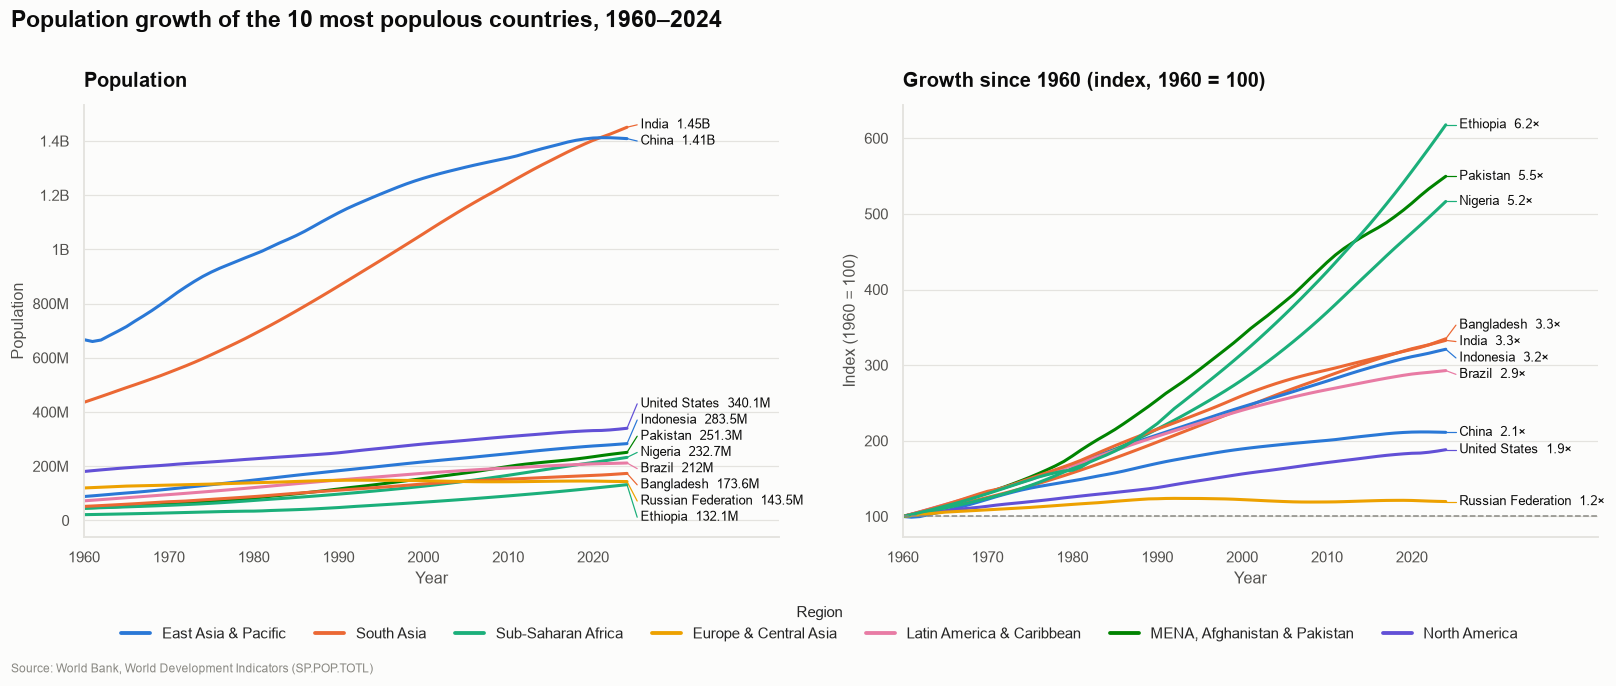

In [17]:
fig = plot_population_growth(df, n=10, year=YEAR, save=True)
plt.show()

In [18]:
world = df.groupby("year")["population"].sum()
regional = df.groupby(["region", "year"])["population"].sum().unstack()
growth = pd.DataFrame({
    "share_1960_%": regional[1960] / regional[1960].sum() * 100,
    f"share_{YEAR}_%": regional[YEAR] / regional[YEAR].sum() * 100,
    "growth_x": regional[YEAR] / regional[1960],
}).sort_values("growth_x", ascending=False)
print(f"World (sum of countries): {human_format(world[1960])} in 1960 -> {human_format(world[YEAR])} in {YEAR} "
      f"({world[YEAR] / world[1960]:.1f}x)")
growth

World (sum of countries): 3.01B in 1960 -> 8.12B in 2024 (2.7x)


,share_1960_%,share_2024_%,growth_x
region,,,
Sub-Saharan Africa,7.6,15.9,5.7
"Middle East, North Africa, Afghanistan & Pakistan",5.2,10.0,5.1
South Asia,16.9,20.7,3.3
Latin America & Caribbean,7.3,8.2,3.0
East Asia & Pacific,34.3,29.1,2.3
North America,6.6,4.7,1.9
Europe & Central Asia,22.2,11.4,1.4


**💡 Insight: the world's population center is shifting south.**

* The world grew **2.7×**, from 3.0B to 8.1B, since 1960.
* **China's population peaked in 2021** and is now flat-to-declining. India kept climbing and passed it.
* The fastest growth among the giants is in **Ethiopia (6.2×), Pakistan (5.5×) and Nigeria (5.2×)**. **Russia (1.2×)** has barely grown since 1960.
* At the regional level, **Sub-Saharan Africa's share of world population doubled** (7.6% → 15.9%), while **Europe & Central Asia's halved** (22.2% → 11.4%).

## 9. Bonus: interactive world map

Hover over a country for its exact population, region and income group. The color scale is **logarithmic**; a linear scale would color almost every country the same pale blue except India and China.

In [19]:
map_fig = plot_choropleth(df, YEAR, save=True)
map_fig.show()

*Static preview, for viewers where the interactive map does not render (e.g. GitHub):*

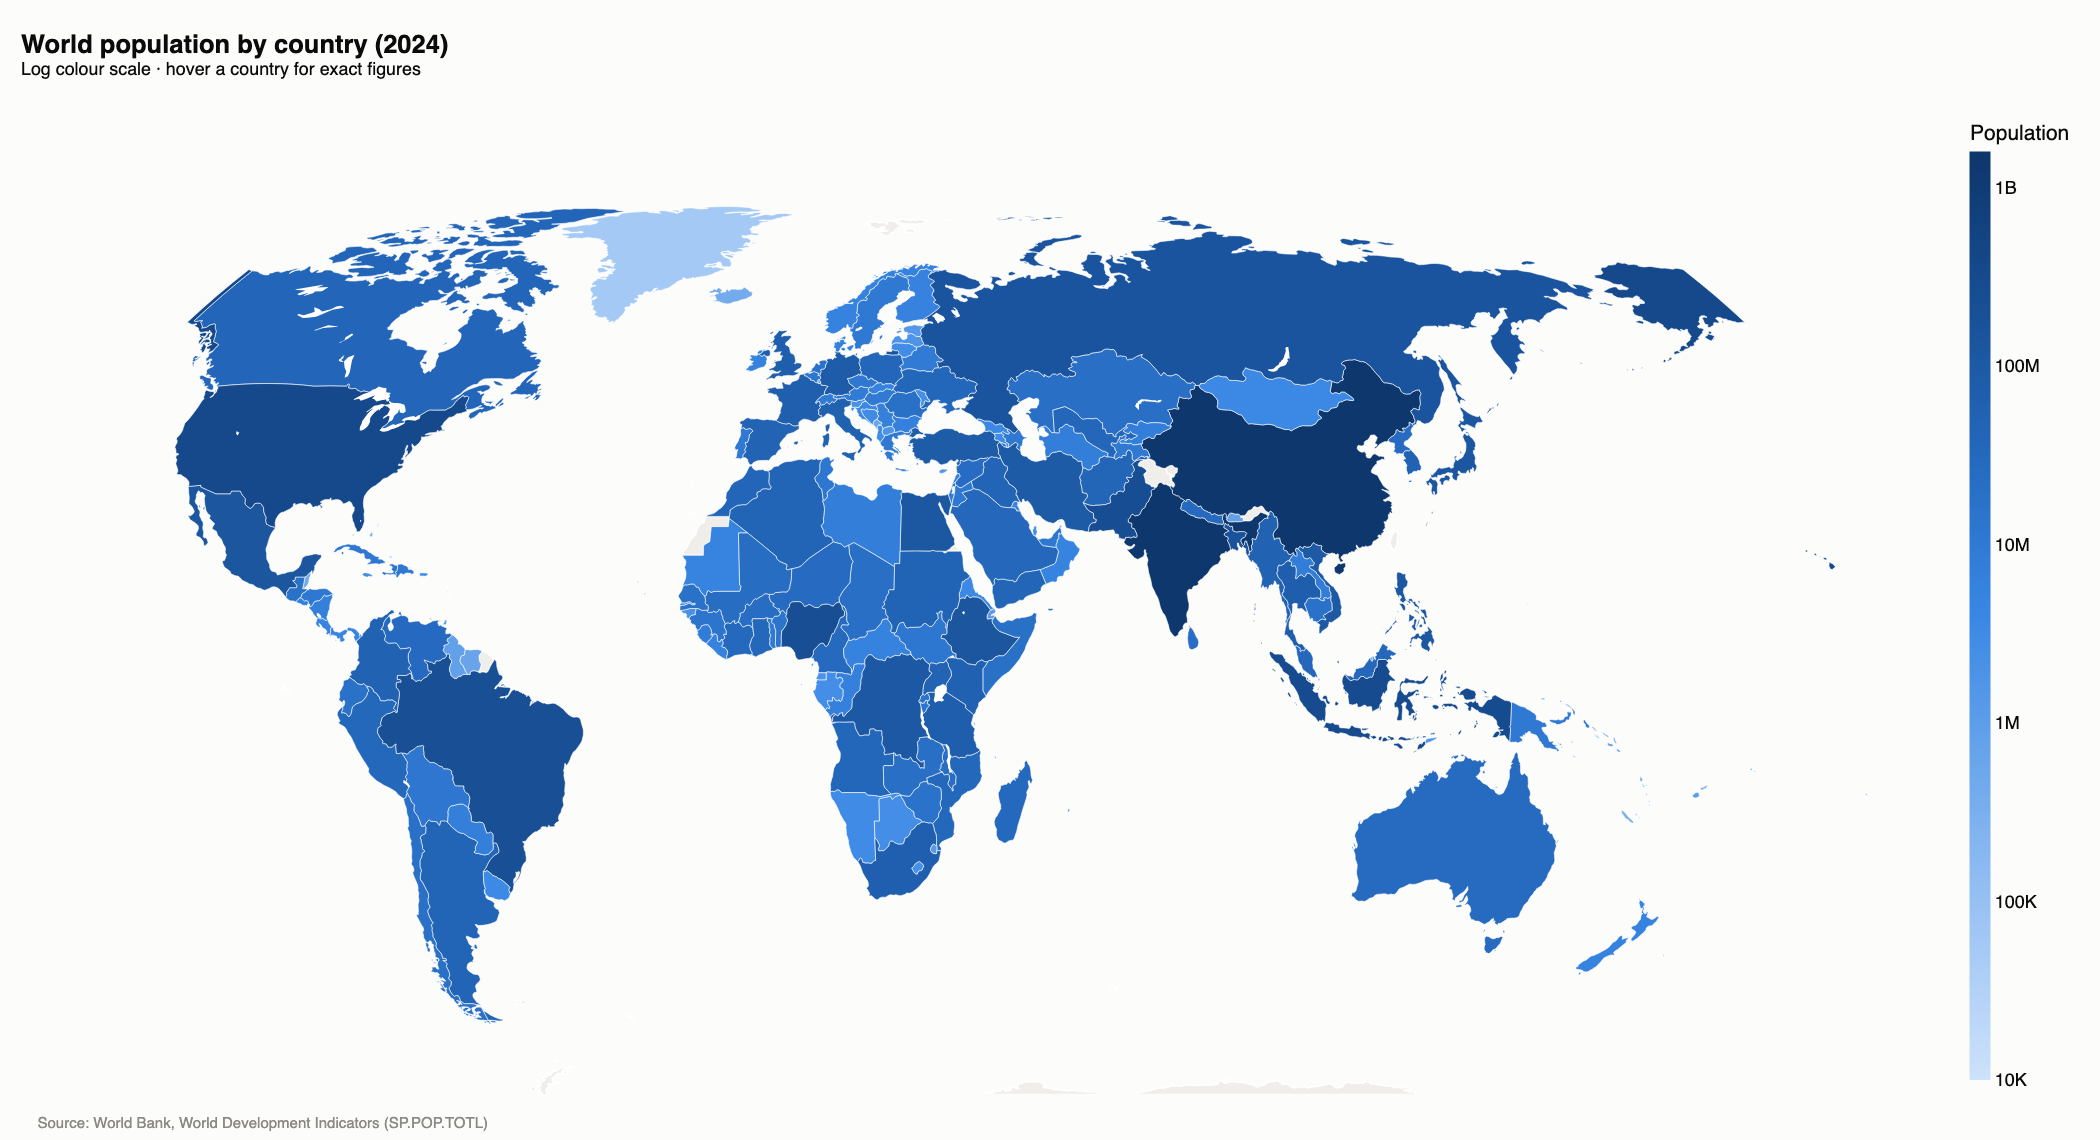

In [20]:
png = FIGURES_DIR / "06_world_population_map.png"
if png.exists():
    display(Image(filename=str(png), width=900))

## 10. Conclusions

| # | Finding | Evidence |
|---|---|---|
| 1 | Country populations are **extremely right-skewed**. The median country has 6.6M people, but the mean is 37M. | Histogram (§4) |
| 2 | **Two countries hold 35%** of humanity. The top 10 hold 57%, and the smallest half of countries hold under 3%. | Top-15 bar chart (§5) |
| 3 | **India overtook China in 2021**, and China's population has peaked. | Growth chart (§8) |
| 4 | **South Asia has 1 in 5 people in just 6 countries.** Europe & Central Asia has the most countries (58) but 11% of people. | Region bar chart (§6) |
| 5 | **Most countries are high-income, but 73% of people live in middle-income countries.** | Income bar charts (§7) |
| 6 | **Growth is shifting to Africa and South Asia.** Sub-Saharan Africa's share doubled since 1960, while Europe's halved. | Growth table (§8) |

**Methodological takeaways**
* Always **remove aggregate rows** from World Bank data before ranking or summing.
* For heavily skewed counts, a **log-scale histogram** (and the **median**) describes the data far better than a linear one (and the mean).
* Comparing a categorical distribution **by count and by weight** (countries vs people) shows patterns that either view alone would miss.

**Limitations and next steps**
* Population is a single total. With a gender/age dataset (e.g. `SP.POP.TOTL.FE.IN`, age-band indicators), the same pipeline could produce population pyramids.
* Values are mid-year estimates and are revised by the World Bank over time.
* Region and income group are **current** classifications applied to all past years.

All figures are saved in `reports/figures/`, and the cleaned data is in `data/processed/population_long.csv`.